<a href="https://colab.research.google.com/github/miriamamin1213-ux/ValidationSET/blob/main/HecktorDT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive


Downloading...
From: https://drive.google.com/uc?id=1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv
To: /content/HPV2025.xlsx
100%|██████████| 66.0k/66.0k [00:00<00:00, 18.6MB/s]


Dataset Shape: (588, 10)

Class Distribution
HPV_Label
0     58
1    530
Name: count, dtype: int64

Rows: 588 | Train: 381 | Validation: 89 | Test: 118
Class counts (train): {0: 37, 1: 344}
Class counts (validation): {0: 9, 1: 80}
Class counts (test): {0: 12, 1: 106}
Number of Features: 8
Encoded Features: 23
Automatic class weights: {0: np.float64(5.148648648648648), 1: np.float64(0.5537790697674418)}
SMOTE: False
Selected parameters: {'ccp_alpha': 0.0, 'class_weight': {0: np.float64(5.148648648648648), 1: np.float64(0.5537790697674418)}, 'criterion': 'gini', 'max_depth': 4, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 2, 'min_samples_split': 10, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}

TEST METRICS
 Accuracy             0.686441
Balanced_Accuracy    0.603774
Precision            0.925926
Recall               0.707547
F1                   0.802139
ROC_AUC              0.568789
PR

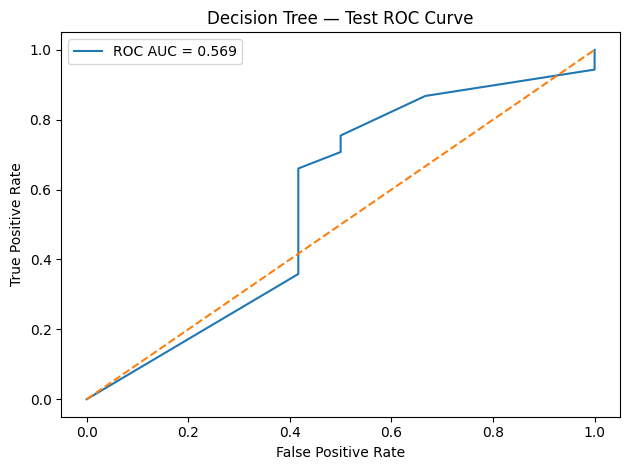

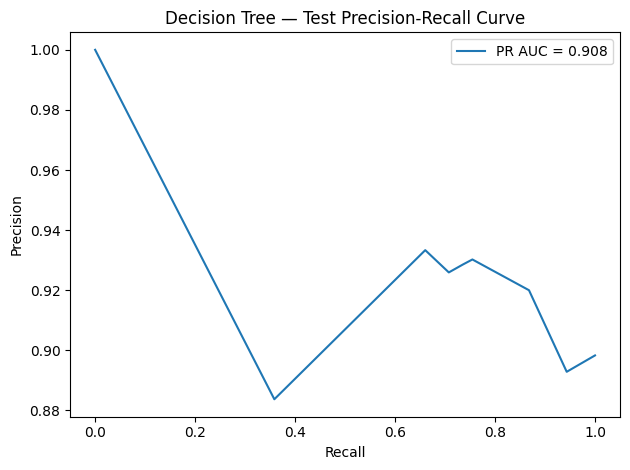

Saved results to: /content/drive/MyDrive/DT_results_HECKTOR


In [1]:
# ============================================================
# DECISION TREE — HECKTOR HPV CLASSIFIER
# Shared data preparation | Seed 42 | No SMOTE
# Same validation and evaluation methodology as HANCOCK
# ============================================================

!pip install -q gdown

import os, json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gdown

from google.colab import drive
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report, roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

drive.mount("/content/drive")

# ------------------------------------------------------------
# 1. LOAD AND PREPARE DATA
# ------------------------------------------------------------

gdown.download(
    id="1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv",
    output="HPV2025.xlsx",
    quiet=False
)

BASE = "/content/drive/MyDrive"
OUT_DIR = os.path.join(BASE, "DT_results_HECKTOR")
os.makedirs(OUT_DIR, exist_ok=True)

df = pd.read_excel("HPV2025.xlsx")

df = df.dropna(subset=["HPV Status"]).copy()

# Keep patient ID for saved predictions, but never use it as a predictor.
if "PatientID" in df.columns:
    df = df.rename(columns={"PatientID": "patient_id"})
else:
    df["patient_id"] = np.arange(len(df))

df["HPV_Label"] = pd.to_numeric(
    df["HPV Status"], errors="coerce"
)

df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)

# ------------------------------------------------------------
# SELECT EXACTLY EIGHT FEATURES
# ------------------------------------------------------------

features = [
    "Age",
    "Gender",
    "Tobacco Consumption",
    "Alcohol Consumption",
    "Performance Status",
    "T-stage",
    "N-stage",
    "M-stage"
]

missing_features = [c for c in features if c not in df.columns]
if missing_features:
    raise KeyError(f"Missing predictor columns: {missing_features}")

df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

df = df[["patient_id"] + features + ["HPV_Label"]].copy()

print("Dataset Shape:", df.shape)
print("\nClass Distribution")
print(df["HPV_Label"].value_counts().sort_index())

# ------------------------------------------------------------
# STRATIFIED TRAIN / VALIDATION / TEST SPLIT (65/15/20)
# ------------------------------------------------------------

train_val, test = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["HPV_Label"]
)

train, val = train_test_split(
    train_val,
    test_size=0.1875,
    random_state=SEED,
    stratify=train_val["HPV_Label"]
)

train = train.copy()
val = val.copy()
test = test.copy()

print(
    "\nRows:", len(df),
    "| Train:", len(train),
    "| Validation:", len(val),
    "| Test:", len(test)
)
print(
    "Class counts (train):",
    train["HPV_Label"].value_counts().sort_index().to_dict()
)
print(
    "Class counts (validation):",
    val["HPV_Label"].value_counts().sort_index().to_dict()
)
print(
    "Class counts (test):",
    test["HPV_Label"].value_counts().sort_index().to_dict()
)

# ------------------------------------------------------------
# MISSING VALUES AND ENCODING
# Fit preprocessing on training data only
# ------------------------------------------------------------

numeric_features = ["Age"]
categorical_features = [
    c for c in features if c not in numeric_features
]

try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

preprocessor = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]),
        numeric_features
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", encoder)
        ]),
        categorical_features
    )
])

X_train = preprocessor.fit_transform(train[features])
X_val = preprocessor.transform(val[features])
X_test = preprocessor.transform(test[features])

y_train = train["HPV_Label"].to_numpy()
y_val = val["HPV_Label"].to_numpy()
y_test = test["HPV_Label"].to_numpy()

counts = np.bincount(y_train, minlength=2)
class_weights = {
    i: len(y_train) / (2 * counts[i])
    for i in range(2)
}

print("Number of Features:", len(features))
print("Encoded Features:", X_train.shape[1])
print("Automatic class weights:", class_weights)
print("SMOTE: False")

# ------------------------------------------------------------
# 2. SELECT TREE SETTINGS USING VALIDATION DATA ONLY
# ------------------------------------------------------------

grid = {
    "max_depth": [2, 3, 4, 5, 7, None],
    "min_samples_split": [2, 5, 10, 15],
    "min_samples_leaf": [2, 5, 10],
    "criterion": ["gini", "entropy"]
}

best_model = None
best_threshold = 0.5
best_key = None
tuning_rows = []

for params in ParameterGrid(grid):
    candidate = DecisionTreeClassifier(
        **params,
        class_weight=class_weights,
        random_state=SEED
    )

    candidate.fit(X_train, y_train)

    val_prob = candidate.predict_proba(X_val)[:, 1]
    thresholds = np.linspace(0.10, 0.90, 81)

    scores = [
        balanced_accuracy_score(
            y_val,
            (val_prob >= t).astype(int)
        )
        for t in thresholds
    ]

    max_score = max(scores)

    threshold = min(
        (
            t for t, score in zip(thresholds, scores)
            if score == max_score
        ),
        key=lambda t: abs(t - 0.5)
    )

    val_pred = (val_prob >= threshold).astype(int)

    auc = (
        roc_auc_score(y_val, val_prob)
        if len(np.unique(y_val)) == 2
        else 0.5
    )

    pr_auc = average_precision_score(y_val, val_prob)

    key = (max_score, auc, pr_auc)

    tuning_rows.append({
        **params,
        "validation_balanced_accuracy": max_score,
        "validation_roc_auc": auc,
        "validation_pr_auc": pr_auc,
        "threshold": float(threshold)
    })

    if best_key is None or key > best_key:
        best_key = key
        best_model = candidate
        best_threshold = float(threshold)

pd.DataFrame(tuning_rows).sort_values(
    [
        "validation_balanced_accuracy",
        "validation_roc_auc",
        "validation_pr_auc"
    ],
    ascending=False
).to_csv(
    os.path.join(OUT_DIR, "validation_tuning.csv"),
    index=False
)

# ------------------------------------------------------------
# 3. FINAL TEST EVALUATION AND SAVE OUTPUTS
# ------------------------------------------------------------

test_prob = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

metrics = {
    "Accuracy": accuracy_score(y_test, test_pred),
    "Balanced_Accuracy": balanced_accuracy_score(y_test, test_pred),
    "Precision": precision_score(y_test, test_pred, zero_division=0),
    "Recall": recall_score(y_test, test_pred, zero_division=0),
    "F1": f1_score(y_test, test_pred, zero_division=0),
    "ROC_AUC": (
        roc_auc_score(y_test, test_prob)
        if len(np.unique(y_test)) == 2
        else np.nan
    ),
    "PR_AUC": average_precision_score(y_test, test_prob),
    "Threshold": best_threshold
}

print("Selected parameters:", best_model.get_params())
print("\nTEST METRICS\n", pd.Series(metrics))
print("\nConfusion matrix:\n", confusion_matrix(y_test, test_pred))
print(
    "\nClassification report:\n",
    classification_report(y_test, test_pred, zero_division=0)
)

pd.DataFrame([metrics]).to_csv(
    os.path.join(OUT_DIR, "metrics.csv"),
    index=False
)

pd.DataFrame({
    "patient_id": test["patient_id"].to_numpy(),
    "y_true": y_test,
    "probability_positive": test_prob,
    "prediction": test_pred
}).to_csv(
    os.path.join(OUT_DIR, "test_predictions.csv"),
    index=False
)

try:
    feature_names = preprocessor.get_feature_names_out()

    importance = pd.DataFrame({
        "feature": feature_names,
        "importance": best_model.feature_importances_
    }).sort_values("importance", ascending=False)

    importance.to_csv(
        os.path.join(OUT_DIR, "feature_importance.csv"),
        index=False
    )

except Exception as e:
    print("Could not export feature names:", e)

with open(os.path.join(OUT_DIR, "settings.json"), "w") as f:
    json.dump({
        "model": "Decision Tree",
        "dataset": "HECKTOR",
        "seed": SEED,
        "features": features,
        "number_of_features": len(features),
        "target_column": "HPV Status",
        "best_parameters": best_model.get_params(),
        "threshold": best_threshold,
        "class_weight": class_weights,
        "smote": False,
        "split": {
            "train": len(train),
            "validation": len(val),
            "test": len(test)
        }
    }, f, indent=2, default=str)

# ------------------------------------------------------------
# ROC / AUC AND PRECISION-RECALL CURVES
# ------------------------------------------------------------

if len(np.unique(y_test)) == 2:
    fpr, tpr, _ = roc_curve(y_test, test_prob)

    plt.figure()
    plt.plot(
        fpr,
        tpr,
        label=f"ROC AUC = {metrics['ROC_AUC']:.3f}"
    )
    plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Decision Tree — Test ROC Curve")
    plt.legend()
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUT_DIR, "roc_curve.png"),
        dpi=150
    )
    plt.show()

    precision, recall, _ = precision_recall_curve(
        y_test, test_prob
    )

    plt.figure()
    plt.plot(
        recall,
        precision,
        label=f"PR AUC = {metrics['PR_AUC']:.3f}"
    )
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Decision Tree — Test Precision-Recall Curve")
    plt.legend()
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUT_DIR, "pr_curve.png"),
        dpi=150
    )
    plt.show()

print("Saved results to:", OUT_DIR)